<a href="https://colab.research.google.com/github/GAEL328530/Lab-pdi-PR-CTICAS/blob/main/Pr%C3%A1ctica_9_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Mejora de iluminación en el espacio de color HSV

Importo las librerías que voy a usar: OpenCV para trabajar con la imagen y Matplotlib para mostrar los resultados.

In [6]:
import cv2
import matplotlib.pyplot as plt

Defino la lista de imágenes a procesar: la imagen original de la práctica y dos imágenes médicas a color (histología y dermatoscopia). Para cada una repito los mismos pasos: la cargo, la convierto a HSV, separo los canales H, S y V, ecualizo solo el canal V (brillo) y regreso la imagen a RGB para visualizarla. Guardo las originales y las mejoradas en dos listas.

In [7]:
imagenes = ["/content/IMAGEN PDI9.jpg", "/content/histologia.jpg", "/content/dermatoscopia.png"]

originales = []
mejoradas = []

for ruta in imagenes:
    img_bgr = cv2.imread(ruta)

    if img_bgr is None:
        raise FileNotFoundError(f"No se encontró {ruta}, hay que subirla primero")

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(img_hsv)

    v_eq = cv2.equalizeHist(v)
    img_hsv_eq = cv2.merge([h, s, v_eq])

    img_eq_bgr = cv2.cvtColor(img_hsv_eq, cv2.COLOR_HSV2BGR)
    img_eq_rgb = cv2.cvtColor(img_eq_bgr, cv2.COLOR_BGR2RGB)

    originales.append(img_rgb)
    mejoradas.append(img_eq_rgb)

Por último, muestro los resultados en una cuadrícula: cada fila es una imagen, con la original a la izquierda y la mejorada a la derecha, para comparar el cambio de iluminación en cada caso.

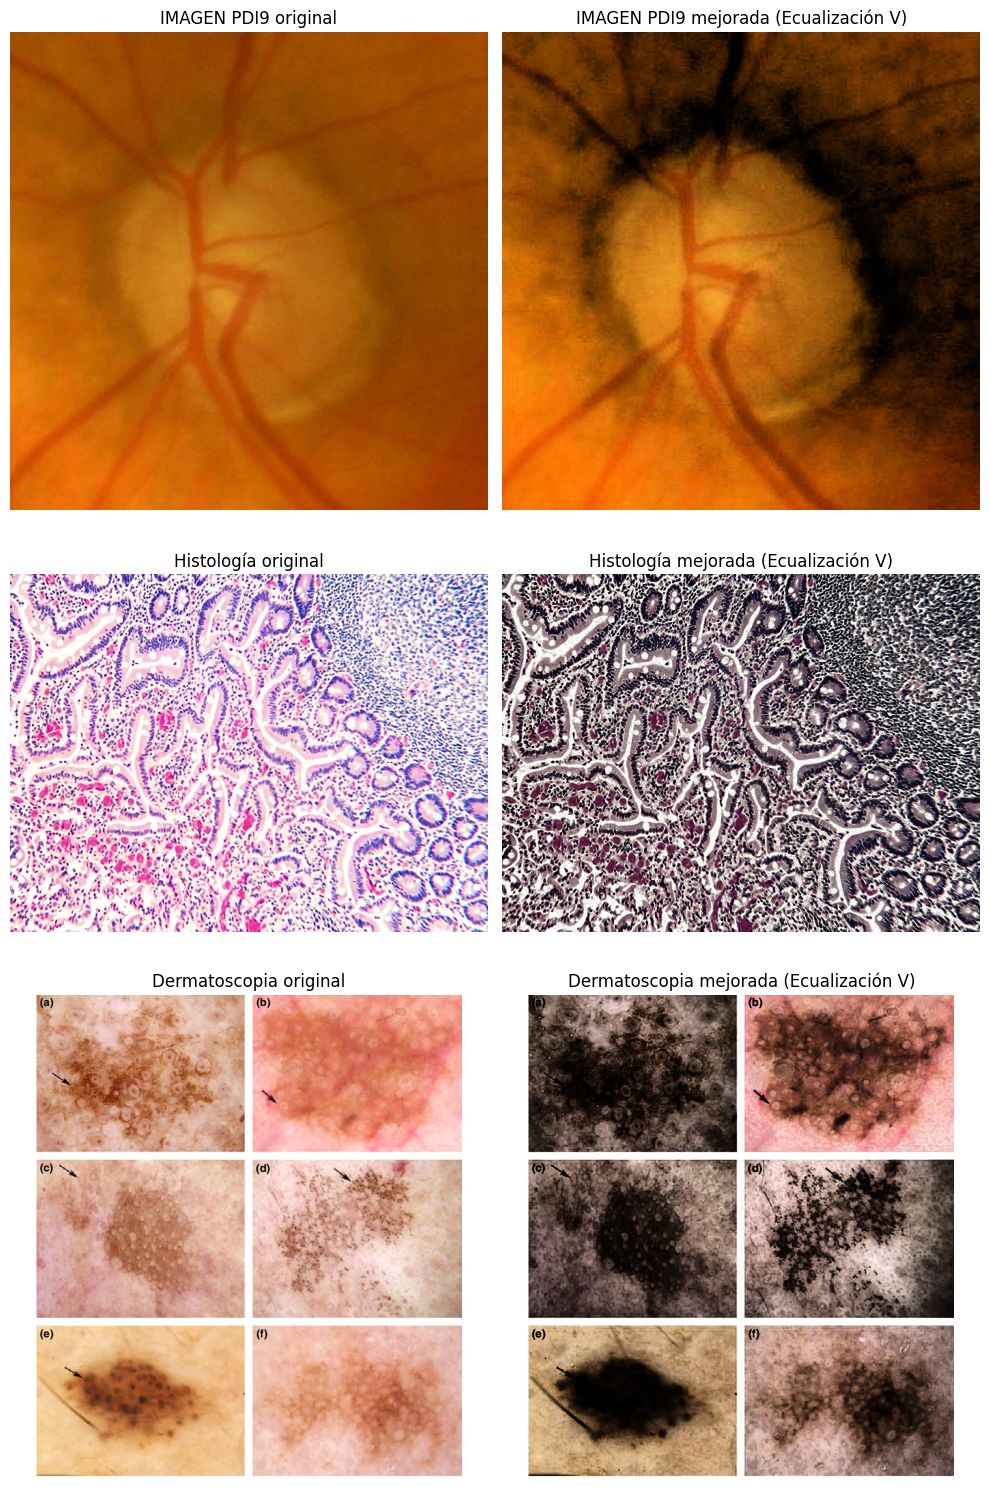

In [8]:
nombres = ["IMAGEN PDI9", "Histología", "Dermatoscopia"]

plt.figure(figsize=(10, 15))

for i in range(3):
    plt.subplot(3, 2, 2 * i + 1)
    plt.imshow(originales[i])
    plt.title(f"{nombres[i]} original")
    plt.axis("off")

    plt.subplot(3, 2, 2 * i + 2)
    plt.imshow(mejoradas[i])
    plt.title(f"{nombres[i]} mejorada (Ecualización V)")
    plt.axis("off")

plt.tight_layout()
plt.show()